In [1]:
import os
import random
import pandas as pd
import numpy as np
import cv2
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
def get_random_images(filepath, n=50000):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [3]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [4]:
def get_imdb_data(imdb_id, imdbCSV):
    """Get IMDB data from the specified CSV file."""
    try:
        tmpDF = pd.read_csv(imdbCSV)
        row = tmpDF[tmpDF['imdb_id'] == imdb_id]
        
        # Include genres in the returned data
        genres = [genre.strip() for genre in row['genres'].iloc[0].split(',')]
        
        show_data = {
            'imdb_id': imdb_id,
            'title': row['title'].iloc[0],
            'rating': row['rating'].iloc[0],
            'rating_count': row['rating_count'].iloc[0],
            'content_rating': row['content_rating'].iloc[0] if 'content_rating' in row.columns else '',
            'date_published': row['date_published'].iloc[0],
            'genres': genres
        }
        return show_data
    except Exception as e:
        return None

In [5]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [6]:
def create_dataset(image_folder, imdbCSV):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id, imdbCSV)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            color_features = extract_color_features(img_path)

            if color_features is not None:
                tempyear = show_data['date_published'][:4]
                genres = show_data['genres']
                
                combined_data = {
                    'imdb_id': imdb_id,
                    'r_mean': color_features[0],
                    'g_mean': color_features[1],
                    'b_mean': color_features[2],
                    'w_mean': color_features[3],
                    'rating': show_data['rating'],
                    'year': int(tempyear),
                    'genres': genres
                }
                data.append(combined_data)
    
    df = pd.DataFrame(data)
    
    # Create one-hot encoding for genres
    all_genres = []
    for genres in df['genres']:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create genre columns
    for genre in unique_genres:
        df[f'genre_{genre}'] = df['genres'].apply(lambda x: 1 if genre in x else 0)
    
    return df

In [7]:
def perform_pca_analysis(df):
    """Perform PCA on non-genre features only."""
    # Identify numerical features (excluding genre and id)
    numerical_columns = ['r_mean', 'g_mean', 'b_mean', 'w_mean', 'rating', 'year']
    
    # Separate genres for later use
    genre_columns = [col for col in df.columns if col.startswith('genre_')]
    genres_df = df[genre_columns]
    
    # Prepare feature matrix for numerical features
    X = df[numerical_columns]
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Save the scaler
    joblib.dump(scaler, 'scaler.pkl')
    print("Scaler model saved as scaler.pkl")
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    # Save the PCA model
    joblib.dump(pca, 'pca_model.pkl')
    print(f"PCA model saved as pca_model.pkl with {n_components} components needed for 80% variance.")
    
    # Create a dataframe with PCA components
    pca_df = pd.DataFrame(X_pca[:, :n_components], 
                          columns=[f'PC{i+1}' for i in range(n_components)])
    
    # Add the imdb_id back for reference
    pca_df['imdb_id'] = df['imdb_id']
    
    return pca, pca_df, genres_df, n_components, numerical_columns

In [8]:
def plot_cumulative_explained_variance(pca):
    """Plot the cumulative explained variance ratio."""
    plt.figure(figsize=(8, 5))
    plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title('Cumulative Explained Variance by PCA Components')
    plt.grid(True)
    plt.show()

In [9]:
def print_explained_variance_ratio(pca, n_components):
    """Print the explained variance ratio for each component up to n_components."""
    print("Explained Variance Ratio by Components (up to 80%):")
    for i in range(n_components):
        print(f"PC{i+1}: {pca.explained_variance_ratio_[i]:.4f}")

In [10]:
def plot_pca_scatter(pca_df):
    """Scatter plot of PC1 and PC2."""
    plt.figure(figsize=(10, 7))
    plt.scatter(pca_df['PC1'], pca_df['PC2'], alpha=0.7, edgecolors='k')
    plt.xlabel('Principal Component 1 (PC1)')
    plt.ylabel('Principal Component 2 (PC2)')
    plt.title('Scatter Plot of PC1 and PC2')
    plt.grid(True)
    plt.show()

In [11]:
def print_feature_loadings(pca, feature_names, n_components):
    """Print the feature loadings for the first n_components."""
    loadings = pca.components_[:n_components]
    loadings_df = pd.DataFrame(loadings, columns=feature_names, index=[f'PC{i+1}' for i in range(n_components)])
    print("\nFeature Loadings:")
    print(loadings_df)

In [12]:
def plot_cluster_scatter(pca_df, labels, title):
    """Scatter plot of PC1 and PC2 with cluster labels."""
    plt.figure(figsize=(10, 7))
    plt.scatter(pca_df['PC1'], pca_df['PC2'], c=labels, cmap='viridis', alpha=0.7, edgecolors='k')
    plt.xlabel('Principal Component 1 (PC1)')
    plt.ylabel('Principal Component 2 (PC2)')
    plt.title(title)
    plt.colorbar(label='Cluster')
    plt.grid(True)
    plt.show()

In [13]:
def analyze_clusters(pca_df, n_clusters_range=range(2, 7)):
    """
    Analyze clusters using multiple metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz)
    WITHOUT using genre information
    """
    from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
    
    # Remove imdb_id for clustering
    features_for_clustering = pca_df.drop('imdb_id', axis=1)
    
    # Initialize results storage
    results = []
    best_model = None
    best_score = -np.inf  # Track best silhouette score
    best_method = ""
    best_n_clusters = 0
    
    # K-means evaluation
    for n_clusters in n_clusters_range:
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(features_for_clustering)
        
        sil_score = silhouette_score(features_for_clustering, labels)
        dbi_score = davies_bouldin_score(features_for_clustering, labels)
        chi_score = calinski_harabasz_score(features_for_clustering, labels)
        
        results.append({
            'Method': 'K-means',
            'n_clusters': n_clusters,
            'Silhouette Score': round(sil_score, 3),
            'Davies-Bouldin Index': round(dbi_score, 3),
            'Calinski-Harabasz Index': round(chi_score, 3)
        })
        
        # Track the best model based on Silhouette Score
        if sil_score > best_score:
            best_score = sil_score
            best_model = kmeans
            best_method = "K-Means"
            best_n_clusters = n_clusters
    
    # Hierarchical evaluation
    for n_clusters in n_clusters_range:
        Z = linkage(features_for_clustering, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
        
        sil_score = silhouette_score(features_for_clustering, labels)
        dbi_score = davies_bouldin_score(features_for_clustering, labels)
        chi_score = calinski_harabasz_score(features_for_clustering, labels)
        
        results.append({
            'Method': 'Hierarchical',
            'n_clusters': n_clusters,
            'Silhouette Score': round(sil_score, 3),
            'Davies-Bouldin Index': round(dbi_score, 3),
            'Calinski-Harabasz Index': round(chi_score, 3)
        })
        
        if sil_score > best_score:
            best_score = sil_score
            best_model = {
                'linkage': Z,
                'n_clusters': n_clusters
            }
            best_method = "Hierarchical"
            best_n_clusters = n_clusters
    
    # DBSCAN evaluation with different eps values
    for eps in [0.3, 0.5, 0.7, 1.0]:
        dbscan = DBSCAN(eps=eps, min_samples=5)
        labels = dbscan.fit_predict(features_for_clustering)
        
        # Only calculate scores if DBSCAN found more than one cluster and no noise points
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters > 1 and -1 not in labels:
            sil_score = silhouette_score(features_for_clustering, labels)
            dbi_score = davies_bouldin_score(features_for_clustering, labels)
            chi_score = calinski_harabasz_score(features_for_clustering, labels)
            
            results.append({
                'Method': f'DBSCAN (eps={eps})',
                'n_clusters': n_clusters,
                'Silhouette Score': round(sil_score, 3),
                'Davies-Bouldin Index': round(dbi_score, 3),
                'Calinski-Harabasz Index': round(chi_score, 3)
            })
            
            if sil_score > best_score:
                best_score = sil_score
                best_model = dbscan
                best_method = f"DBSCAN (eps={eps})"
                best_n_clusters = n_clusters
    
    # GMM evaluation
    for n_clusters in n_clusters_range:
        gmm = GaussianMixture(n_components=n_clusters, random_state=42)
        labels = gmm.fit_predict(features_for_clustering)
        
        sil_score = silhouette_score(features_for_clustering, labels)
        dbi_score = davies_bouldin_score(features_for_clustering, labels)
        chi_score = calinski_harabasz_score(features_for_clustering, labels)
        
        results.append({
            'Method': 'GMM',
            'n_clusters': n_clusters,
            'Silhouette Score': round(sil_score, 3),
            'Davies-Bouldin Index': round(dbi_score, 3),
            'Calinski-Harabasz Index': round(chi_score, 3)
        })
        
        if sil_score > best_score:
            best_score = sil_score
            best_model = gmm
            best_method = "GMM"
            best_n_clusters = n_clusters
    
    # BIRCH evaluation
    for n_clusters in n_clusters_range:
        birch = Birch(n_clusters=n_clusters)
        labels = birch.fit_predict(features_for_clustering)
        
        sil_score = silhouette_score(features_for_clustering, labels)
        dbi_score = davies_bouldin_score(features_for_clustering, labels)
        chi_score = calinski_harabasz_score(features_for_clustering, labels)
        
        results.append({
            'Method': 'BIRCH',
            'n_clusters': n_clusters,
            'Silhouette Score': round(sil_score, 3),
            'Davies-Bouldin Index': round(dbi_score, 3),
            'Calinski-Harabasz Index': round(chi_score, 3)
        })
        
        if sil_score > best_score:
            best_score = sil_score
            best_model = birch
            best_method = "BIRCH"
            best_n_clusters = n_clusters
    
    # Create DataFrame and sort by Silhouette Score (descending)
    df_results = pd.DataFrame(results)
    df_results = df_results.sort_values('Silhouette Score', ascending=False)
    
    # Print formatted tables
    print("\nClustering Evaluation Results (WITHOUT using genre information):")
    print(df_results.to_string(index=False))
    
    # Create summary of best results
    print("\nBest Results:")
    best_silhouette = df_results.loc[df_results['Silhouette Score'].idxmax()]
    best_davies = df_results.loc[df_results['Davies-Bouldin Index'].idxmin()]
    best_calinski = df_results.loc[df_results['Calinski-Harabasz Index'].idxmax()]
    
    summary = pd.DataFrame([
        {
            'Metric': 'Best Silhouette Score',
            'Method': best_silhouette['Method'],
            'n_clusters': best_silhouette['n_clusters'],
            'Score': best_silhouette['Silhouette Score']
        },
        {
            'Metric': 'Best Davies-Bouldin Index',
            'Method': best_davies['Method'],
            'n_clusters': best_davies['n_clusters'],
            'Score': best_davies['Davies-Bouldin Index']
        },
        {
            'Metric': 'Best Calinski-Harabasz Index',
            'Method': best_calinski['Method'],
            'n_clusters': best_calinski['n_clusters'],
            'Score': best_calinski['Calinski-Harabasz Index']
        }
    ])
    
    print(summary.to_string(index=False))
    
    # Save the best clustering model
    if best_model is not None:
        joblib.dump(best_model, 'best_cluster_model.pkl')
        print(f"Best Model: {best_method} with Silhouette Score: {best_score:.3f} saved as best_cluster_model.pkl")
    
    return best_model, best_method, best_n_clusters, df_results


In [14]:
def plot_all_cluster_scatters(pca_df, best_n_clusters):
    """Plot scatter plots of PC1 and PC2 for all clustering algorithms in one figure."""
    plt.figure(figsize=(20, 12))  # Large figure to accommodate all subplots
    
    # Remove 'imdb_id' for clustering
    features_for_clustering = pca_df.drop('imdb_id', axis=1)
    
    # K-Means
    plt.subplot(2, 3, 1)  # 2 rows, 3 columns, position 1
    kmeans = KMeans(n_clusters=best_n_clusters, random_state=42)
    kmeans_labels = kmeans.fit_predict(features_for_clustering)
    plt.scatter(pca_df['PC1'], pca_df['PC2'], c=kmeans_labels, cmap='viridis', alpha=0.7, edgecolors='k')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('K-Means Clustering')
    
    # Hierarchical Clustering
    plt.subplot(2, 3, 2)  # 2 rows, 3 columns, position 2
    Z = linkage(features_for_clustering, method='ward')
    hierarchical_labels = fcluster(Z, best_n_clusters, criterion='maxclust')
    plt.scatter(pca_df['PC1'], pca_df['PC2'], c=hierarchical_labels, cmap='viridis', alpha=0.7, edgecolors='k')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('Hierarchical Clustering')
    
    # DBSCAN
    plt.subplot(2, 3, 3)  # 2 rows, 3 columns, position 3
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(features_for_clustering)
    plt.scatter(pca_df['PC1'], pca_df['PC2'], c=dbscan_labels, cmap='viridis', alpha=0.7, edgecolors='k')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('DBSCAN Clustering')
    
    # GMM
    plt.subplot(2, 3, 4)  # 2 rows, 3 columns, position 4
    gmm = GaussianMixture(n_components=best_n_clusters, random_state=42)
    gmm_labels = gmm.fit_predict(features_for_clustering)
    plt.scatter(pca_df['PC1'], pca_df['PC2'], c=gmm_labels, cmap='viridis', alpha=0.7, edgecolors='k')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('GMM Clustering')
    
    # BIRCH
    plt.subplot(2, 3, 5)  # 2 rows, 3 columns, position 5
    birch = Birch(n_clusters=best_n_clusters)
    birch_labels = birch.fit_predict(features_for_clustering)
    plt.scatter(pca_df['PC1'], pca_df['PC2'], c=birch_labels, cmap='viridis', alpha=0.7, edgecolors='k')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('BIRCH Clustering')
    
    # Adjust layout and show plot
    plt.tight_layout()
    plt.savefig('all_clustering_results.png')  # Save the figure
    plt.show()


In [15]:
def apply_best_clustering(pca_df, best_model, best_method):
    """Apply the best clustering model to get cluster labels"""
    features_for_clustering = pca_df.drop('imdb_id', axis=1)
    
    if best_method.startswith('K-means'):
        labels = best_model.predict(features_for_clustering)
    elif best_method.startswith('Hierarchical'):
        Z = best_model['linkage']
        n_clusters = best_model['n_clusters']
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    elif best_method.startswith('DBSCAN'):
        labels = best_model.fit_predict(features_for_clustering)
    elif best_method.startswith('GMM'):
        labels = best_model.predict(features_for_clustering)
    elif best_method.startswith('BIRCH'):
        labels = best_model.predict(features_for_clustering)
    else:
        # Default to K-means with 2 clusters if something went wrong
        kmeans = KMeans(n_clusters=2, random_state=42)
        labels = kmeans.fit_predict(features_for_clustering)
    
    # Add cluster labels to the dataframe
    result_df = pca_df.copy()
    result_df['cluster'] = labels
    
    return result_df, labels


In [16]:
def plot_evaluation_metrics_bar_graphs(cluster_results):
    """
    Plot bar graphs for each evaluation metric (Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index).
    X-axis: Clustering algorithms
    Y-axis: Best performing score for each metric.
    """
    # Extract the best scores for each algorithm
    algorithms = cluster_results['Method'].unique()
    silhouette_scores = []
    davies_bouldin_scores = []
    calinski_harabasz_scores = []

    for algo in algorithms:
        # Filter results for the current algorithm
        algo_results = cluster_results[cluster_results['Method'] == algo]
        
        # Get the best score for each metric
        best_silhouette = algo_results['Silhouette Score'].max()
        best_davies = algo_results['Davies-Bouldin Index'].min()  # Lower is better
        best_calinski = algo_results['Calinski-Harabasz Index'].max()
        
        silhouette_scores.append(best_silhouette)
        davies_bouldin_scores.append(best_davies)
        calinski_harabasz_scores.append(best_calinski)

    # Create bar graphs for each metric
    plt.figure(figsize=(18, 5))

    # Silhouette Score
    plt.subplot(1, 3, 1)
    plt.bar(algorithms, silhouette_scores, color='skyblue')
    plt.xlabel('Clustering Algorithm')
    plt.ylabel('Silhouette Score')
    plt.title('Best Silhouette Score by Algorithm')
    plt.ylim(0, 1)  # Silhouette Score ranges from -1 to 1
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Davies-Bouldin Index
    plt.subplot(1, 3, 2)
    plt.bar(algorithms, davies_bouldin_scores, color='lightgreen')
    plt.xlabel('Clustering Algorithm')
    plt.ylabel('Davies-Bouldin Index')
    plt.title('Best Davies-Bouldin Index by Algorithm')
    plt.ylim(0, max(davies_bouldin_scores) + 0.5)  # Adjust y-axis limit
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Calinski-Harabasz Index
    plt.subplot(1, 3, 3)
    plt.bar(algorithms, calinski_harabasz_scores, color='salmon')
    plt.xlabel('Clustering Algorithm')
    plt.ylabel('Calinski-Harabasz Index')
    plt.title('Best Calinski-Harabasz Index by Algorithm')
    plt.ylim(0, max(calinski_harabasz_scores) + 100)  # Adjust y-axis limit
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Adjust layout and show plot
    plt.tight_layout()
    plt.savefig('evaluation_metrics_bar_graphs.png')  # Save the figure
    plt.show()

In [17]:
def calculate_purity_score(clusters, genres):
    """
    Calculate purity score which measures how much each cluster is dominated by a single genre
    Higher is better (1.0 means perfect clusters where each cluster contains only one genre)
    """
    # For each cluster, find the most common genre and count how many items match that genre
    total_correct = 0
    
    # Get dominant genre for each cluster
    for cluster_id in np.unique(clusters):
        cluster_items = (clusters == cluster_id)
        cluster_genres = genres[cluster_items]
        
        # Find most common genre in this cluster
        genre_counts = cluster_genres.sum()
        dominant_genre = genre_counts.idxmax()
        dominant_genre_count = genre_counts.max()
        
        total_correct += dominant_genre_count
    
    return total_correct / len(clusters)

In [18]:
def superimpose_genres_on_clusters(cluster_results_df, genres_df):
    """
    Step 2: Map genres onto clusters and analyze distribution
    """
    # Merge cluster results with genre information
    merged_df = cluster_results_df.copy()
    for col in genres_df.columns:
        merged_df[col] = genres_df[col].values
    
    # Analyze genre distribution within clusters
    clusters = merged_df['cluster'].unique()
    genre_cols = [col for col in genres_df.columns]
    
    # Create a dataframe to store genre distribution by cluster
    genre_distribution = pd.DataFrame(index=clusters, columns=genre_cols)
    
    # Calculate the percentage of each genre in each cluster
    for cluster in clusters:
        cluster_data = merged_df[merged_df['cluster'] == cluster]
        for genre in genre_cols:
            genre_distribution.loc[cluster, genre] = round(cluster_data[genre].mean() * 100, 1)
    
    # Sort to highlight dominant genres per cluster
    sorted_genre_distribution = genre_distribution.copy()
    for cluster in clusters:
        sorted_cols = sorted_genre_distribution.loc[cluster].sort_values(ascending=False).index
        sorted_genre_distribution = sorted_genre_distribution[sorted_cols]
    
    print("\nGenre Distribution by Cluster (percentage):")
    print(genre_distribution)
    
    # Identify dominant genres in each cluster
    dominant_genres = {}
    for cluster in clusters:
        top_genres = genre_distribution.loc[cluster].sort_values(ascending=False).head(3)
        dominant_genres[cluster] = {
            'genres': top_genres.index.tolist(),
            'percentages': top_genres.values.tolist()
        }
    
    print("\nDominant Genres by Cluster:")
    for cluster, data in dominant_genres.items():
        genres_str = ", ".join([f"{genre.replace('genre_', '')} ({pct}%)" 
                               for genre, pct in zip(data['genres'], data['percentages'])])
        print(f"Cluster {cluster}: {genres_str}")
    
    return merged_df, genre_distribution

In [19]:
def save_combined_data(pca_df, cluster_labels, genres_df, filename='combined_data.csv'):
    """
    Combine PCA-transformed data, cluster labels, and genre information into a single DataFrame.
    Save the combined data as a CSV file for use in the GUI application.
    """
    combined_df = df[['imdb_id', 'r_mean', 'g_mean', 'b_mean', 'w_mean', 'rating', 'year']].copy()
    combined_df = pd.concat([combined_df, pca_df, genres_df], axis=1)
    combined_df['cluster'] = cluster_labels
    
    # Save the combined DataFrame to a CSV file
    combined_df.to_csv(filename, index=False)
    print(f"Combined data saved as {filename}")

In [20]:
def validate_clustering_against_genres(cluster_labels, genres_df):
    """
    Step 3: Validate clustering against genres using formal metrics
    """
    # We need to convert multi-label genres to single labels for some metrics
    # For each show, use the primary genre (first genre listed)
    genre_cols = genres_df.columns
    
    # Calculate primary genre for each show (highest genre value)
    primary_genres = genres_df.idxmax(axis=1)
    
    # Calculate Normalized Mutual Information
    nmi_score = normalized_mutual_info_score(primary_genres, cluster_labels)
    
    # Calculate Adjusted Rand Index
    ari_score = adjusted_rand_score(primary_genres, cluster_labels)
    
    # Calculate Purity Score
    purity = calculate_purity_score(cluster_labels, genres_df)
    
    print("\nClustering Validation against Genres:")
    print(f"Normalized Mutual Information: {nmi_score:.3f}")
    print(f"Adjusted Rand Index: {ari_score:.3f}")
    print(f"Purity Score: {purity:.3f}")
    
    # Interpretation
    print("\nInterpretation:")
    if nmi_score > 0.3:
        print("- NMI Score suggests clustering has captured meaningful genre relationships")
    else:
        print("- NMI Score suggests limited alignment between clusters and genres")
        
    if ari_score > 0.2:
        print("- ARI Score indicates clusters align well with genre categories")
    else:
        print("- ARI Score indicates clusters don't strongly align with genre categories")
        
    if purity > 0.5:
        print("- Purity Score shows clusters tend to be dominated by specific genres")
    else:
        print("- Purity Score suggests clusters contain a mix of genres rather than being genre-specific")
    
    return {
        'nmi': nmi_score,
        'ari': ari_score,
        'purity': purity
    }


In [21]:
def visualize_clusters_with_genres(cluster_results_df, genres_df):
    """
    Visualize the clusters with genre information superimposed
    """
    # Extract the first two principal components
    X = cluster_results_df[['PC1', 'PC2']].values
    labels = cluster_results_df['cluster'].values
    
    # Set up the figure
    plt.figure(figsize=(15, 10))
    
    # Create a color map for clusters
    unique_clusters = np.unique(labels)
    cmap = plt.cm.get_cmap('viridis', len(unique_clusters))
    
    # Plot clusters
    scatter = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap=cmap, alpha=0.7, s=50, edgecolors='k')
    
    # Add legend for clusters
    legend1 = plt.legend(*scatter.legend_elements(),
                        loc="upper right", title="Clusters")
    plt.gca().add_artist(legend1)
    
    # Determine dominant genre for each point
    dominant_genres = genres_df.idxmax(axis=1)
    dominant_genres = dominant_genres.apply(lambda x: x.replace('genre_', ''))
    
    # Add text labels for top genres
    for i, (x, y) in enumerate(X):
        # Only label some points to avoid clutter
        if i % 10 == 0:  # Label every 10th point
            plt.annotate(dominant_genres.iloc[i], 
                        (x, y), 
                        fontsize=8,
                        alpha=0.8)
    
    plt.title('Cluster Visualization with Dominant Genres')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('cluster_genre_visualization.png')
    plt.show()

    # Create a heatmap of genre distribution by cluster
    plt.figure(figsize=(15, 8))
    genre_cols = [col.replace('genre_', '') for col in genres_df.columns]
    genre_dist_by_cluster = pd.DataFrame()
    
    for cluster in np.unique(labels):
        cluster_mask = (labels == cluster)
        genre_dist_by_cluster[f'Cluster {cluster}'] = genres_df[cluster_mask].mean()
    
    genre_dist_by_cluster.index = [col.replace('genre_', '') for col in genre_dist_by_cluster.index]
    
    sns.heatmap(genre_dist_by_cluster, cmap='YlOrRd', annot=True, fmt='.2f')
    plt.title('Genre Distribution by Cluster')
    plt.ylabel('Genre')
    plt.xlabel('Cluster')
    plt.tight_layout()
    plt.savefig('genre_cluster_heatmap.png')
    plt.show()

In [22]:
# Step 1: Gathering data and extracting features
IMAGE_FOLDER = "tv_show_posters"
imdbCSV = "tv_shows_data.csv"
df = create_dataset(IMAGE_FOLDER, imdbCSV)

In [23]:
# Step 2: Performing PCA on numerical features
pca, pca_df, genres_df, n_components, feature_names = perform_pca_analysis(df)

Scaler model saved as scaler.pkl
PCA model saved as pca_model.pkl with 3 components needed for 80% variance.


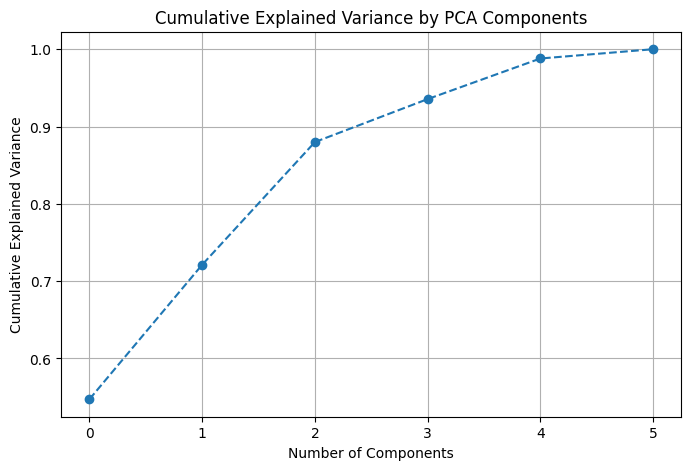

Explained Variance Ratio by Components (up to 80%):
PC1: 0.5472
PC2: 0.1740
PC3: 0.1587


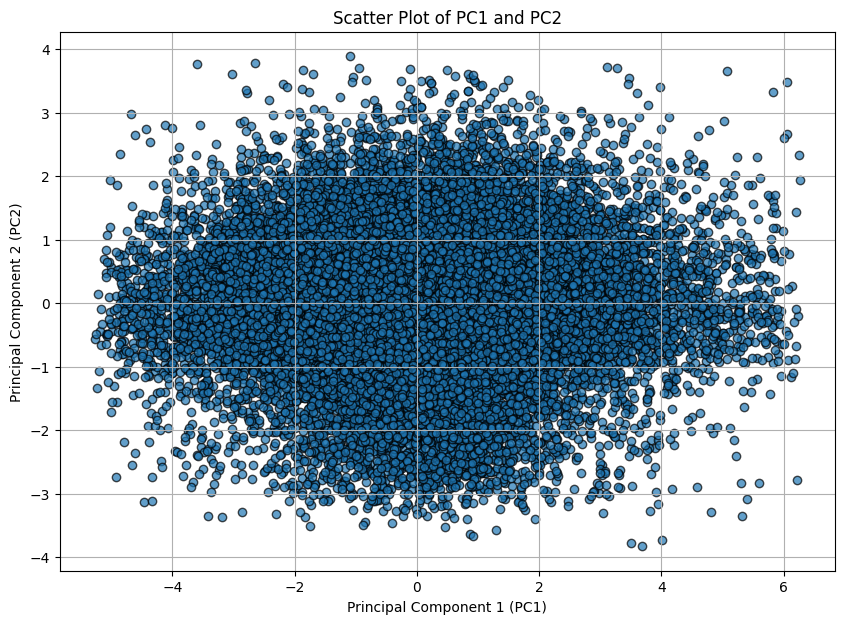


Feature Loadings:
       r_mean    g_mean    b_mean    w_mean    rating      year
PC1  0.493101  0.528983  0.497548  0.476902 -0.034124 -0.029557
PC2 -0.005422 -0.021941  0.008624  0.014636 -0.703385  0.710247
PC3  0.004153  0.026838  0.031028  0.027903  0.709695  0.702748


In [24]:
plot_cumulative_explained_variance(pca)
print_explained_variance_ratio(pca, n_components)
plot_pca_scatter(pca_df)
print_feature_loadings(pca, feature_names, n_components)


In [25]:
# Step 3: Evaluating clustering algorithms
best_model, best_method, best_n_clusters, cluster_results = analyze_clusters(pca_df)


Clustering Evaluation Results (WITHOUT using genre information):
      Method  n_clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
     K-means           2             0.324                 1.148                18306.452
Hierarchical           2             0.303                 1.184                16213.343
     K-means           5             0.301                 1.003                14657.055
     K-means           6             0.296                 1.060                13162.998
     K-means           4             0.290                 1.100                14573.466
       BIRCH           2             0.280                 1.197                13520.250
     K-means           3             0.256                 1.283                14720.503
Hierarchical           6             0.228                 1.146                10391.854
Hierarchical           3             0.225                 1.405                12543.044
Hierarchical           5          

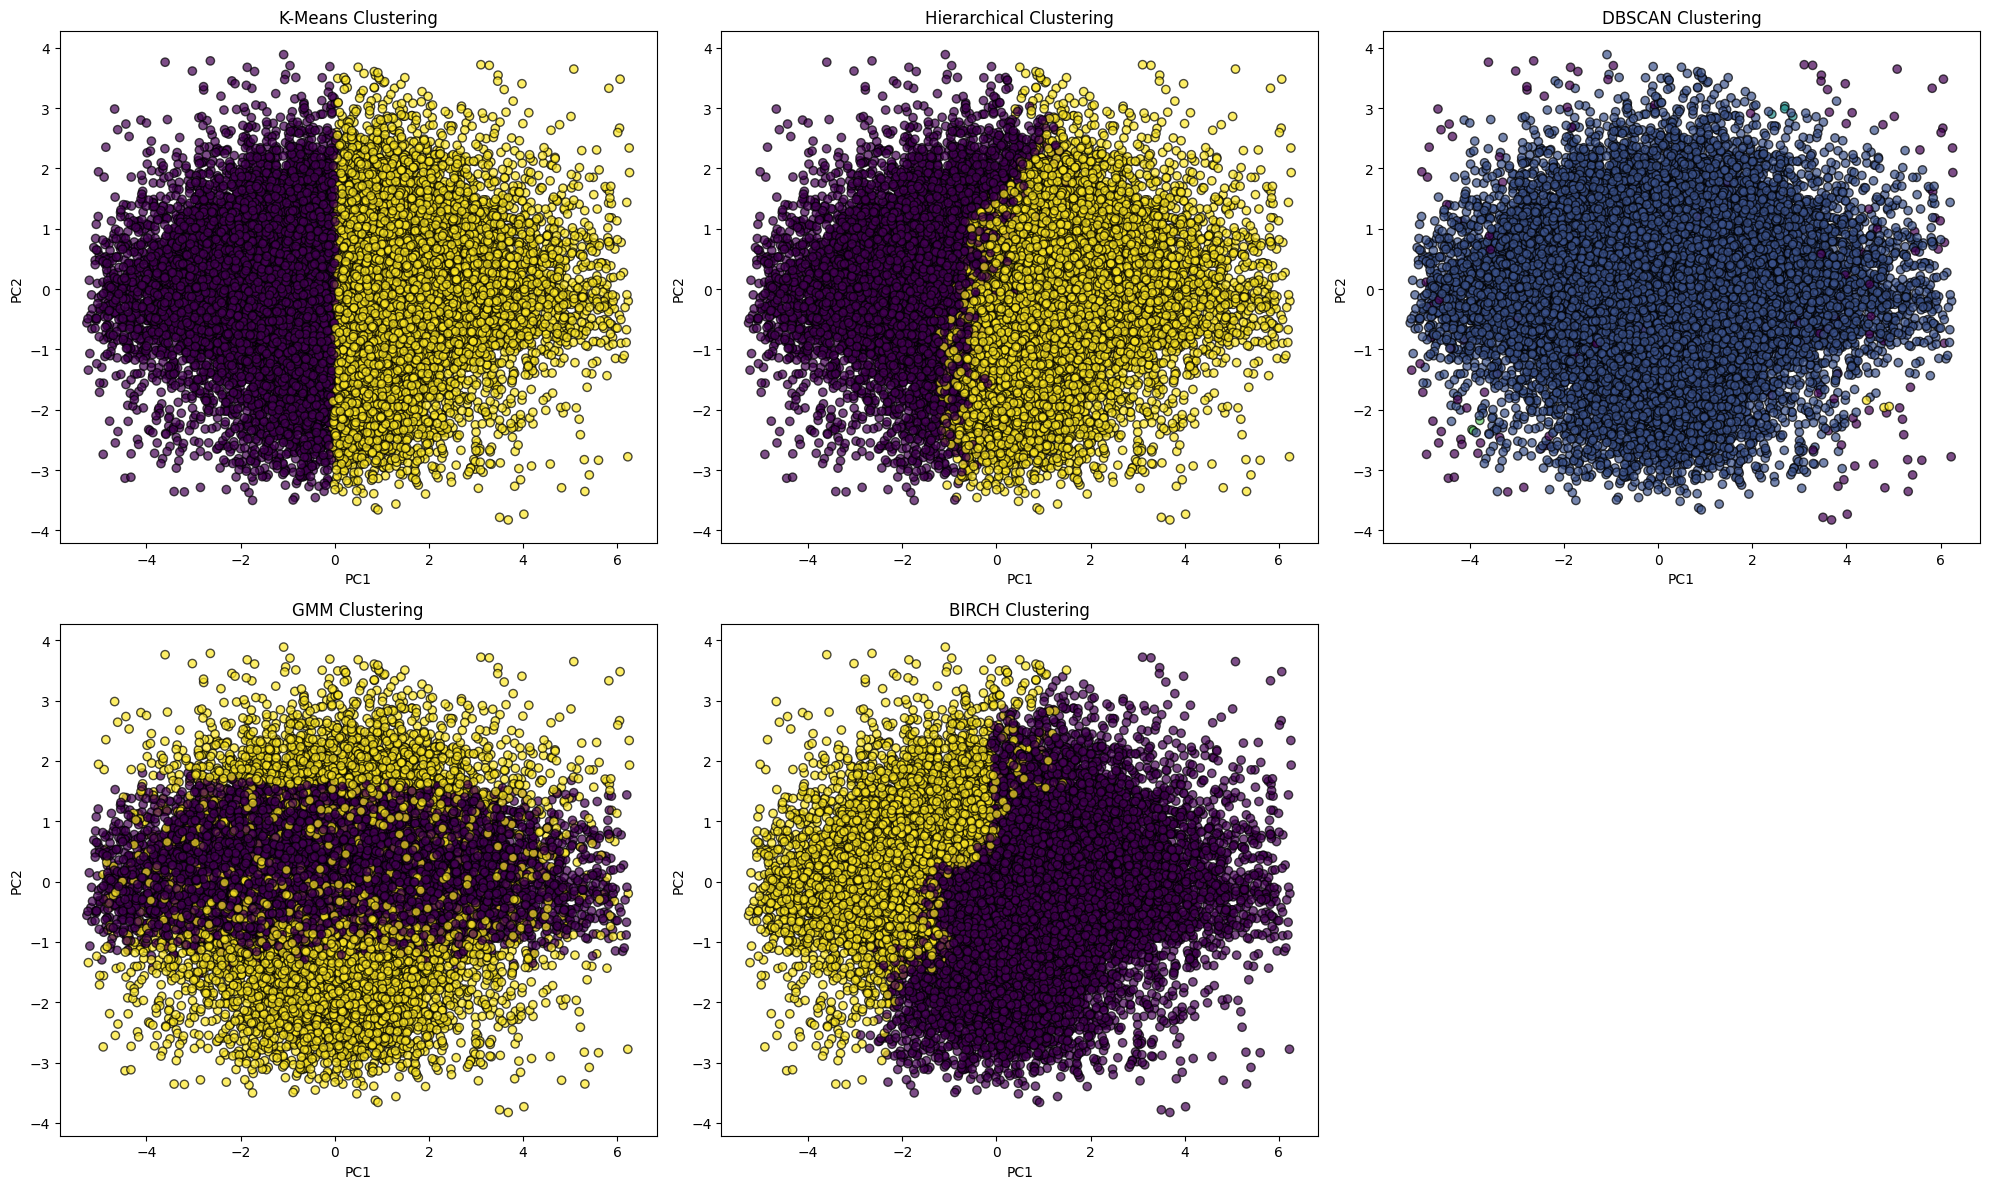

In [26]:
# Call this function after performing PCA and determining the best number of clusters
plot_all_cluster_scatters(pca_df, best_n_clusters)

In [27]:
# Step 4: Applying best clustering model
cluster_results_df, cluster_labels = apply_best_clustering(pca_df, best_model, best_method)

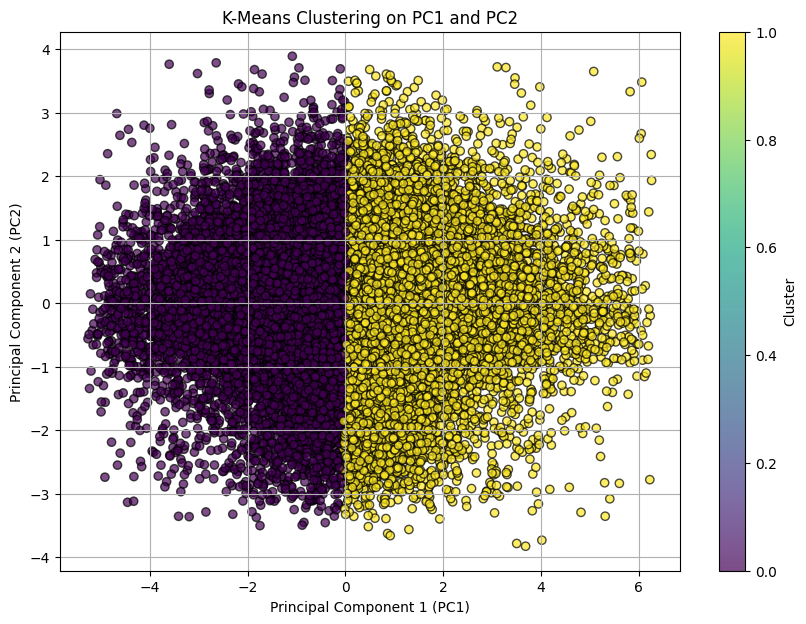

In [28]:
# Scatter plot of PC1 and PC2 for each clustering algorithm
plot_cluster_scatter(pca_df, cluster_labels, f'{best_method} Clustering on PC1 and PC2')

In [29]:
# Step 5: Superimposing genres on clusters
merged_df, genre_distribution = superimpose_genres_on_clusters(cluster_results_df, genres_df)


Genre Distribution by Cluster (percentage):
  genre_Action genre_Adult genre_Adventure genre_Animation genre_Biography  \
0          9.0         0.0             7.4             6.5             2.1   
1          6.8         0.1             9.0            15.5             1.3   

  genre_Comedy genre_Crime genre_Documentary genre_Drama genre_Family  ...  \
0         24.7        12.9              14.5        33.0          5.2  ...   
1         36.1         5.5              10.6        27.8         10.1  ...   

  genre_News genre_Reality-TV genre_Romance genre_Sci-Fi genre_Short  \
0        1.9              8.8           5.5          2.9         1.6   
1        2.0             10.0           9.4          1.7         2.1   

  genre_Sport genre_Talk-Show genre_Thriller genre_War genre_Western  
0         2.5             5.0            4.8       0.9           0.3  
1         2.3             4.5            1.7       0.5           0.5  

[2 rows x 27 columns]

Dominant Genres by Cluster:
Clu

In [30]:
# Step 6: Validating clustering against genres
validation_metrics = validate_clustering_against_genres(cluster_labels, genres_df)


Clustering Validation against Genres:
Normalized Mutual Information: 0.017
Adjusted Rand Index: 0.007
Purity Score: 0.346

Interpretation:
- NMI Score suggests limited alignment between clusters and genres
- ARI Score indicates clusters don't strongly align with genre categories
- Purity Score suggests clusters contain a mix of genres rather than being genre-specific


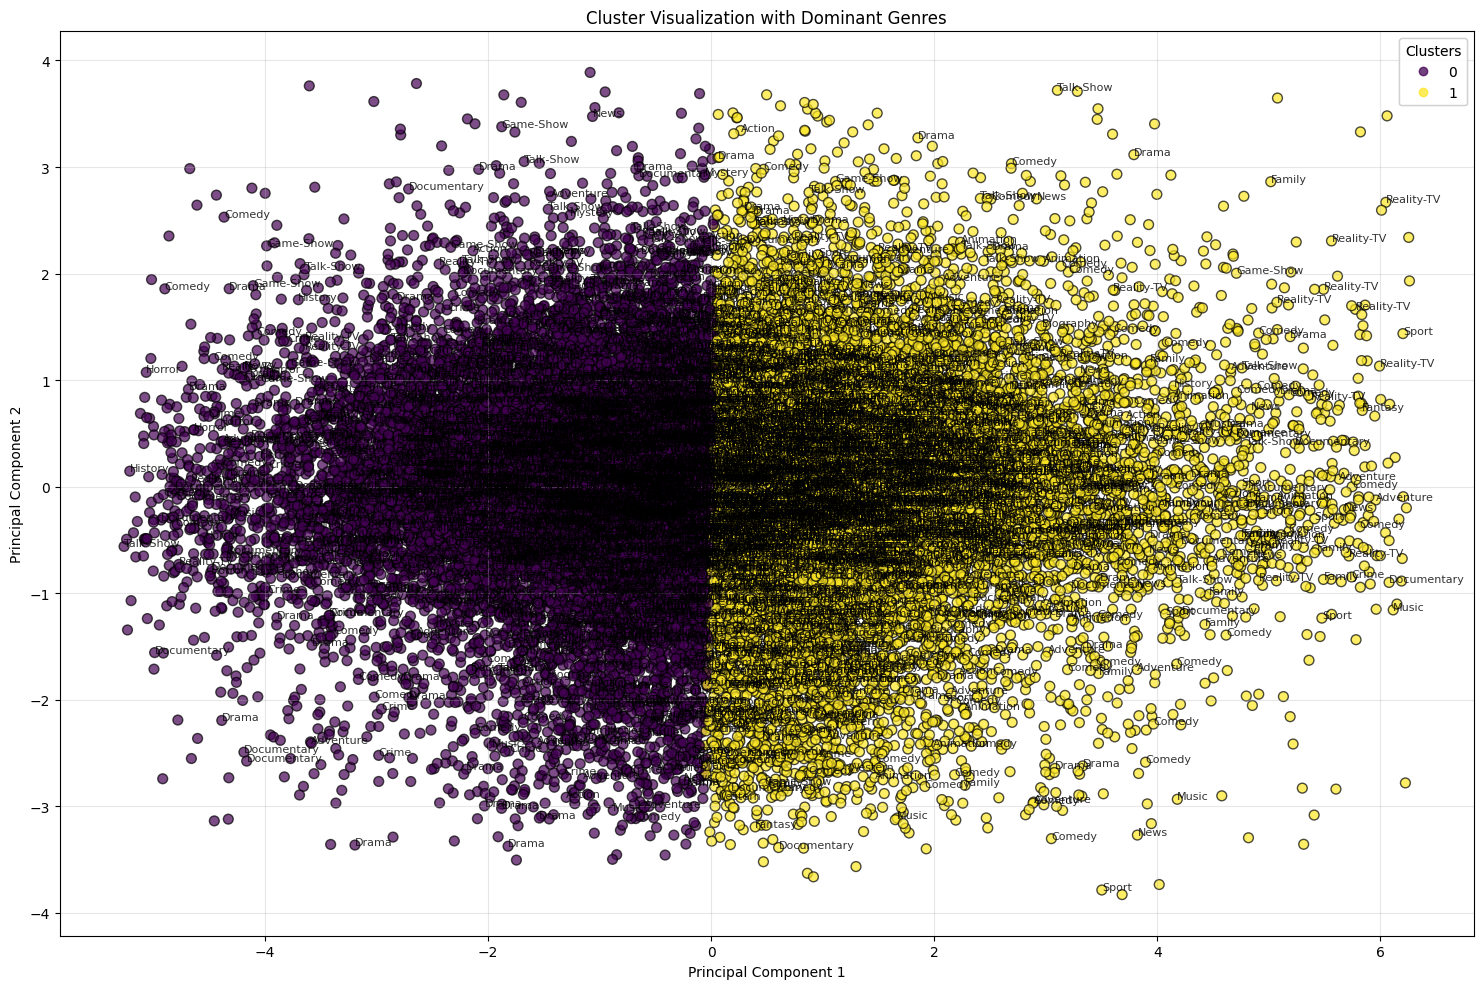

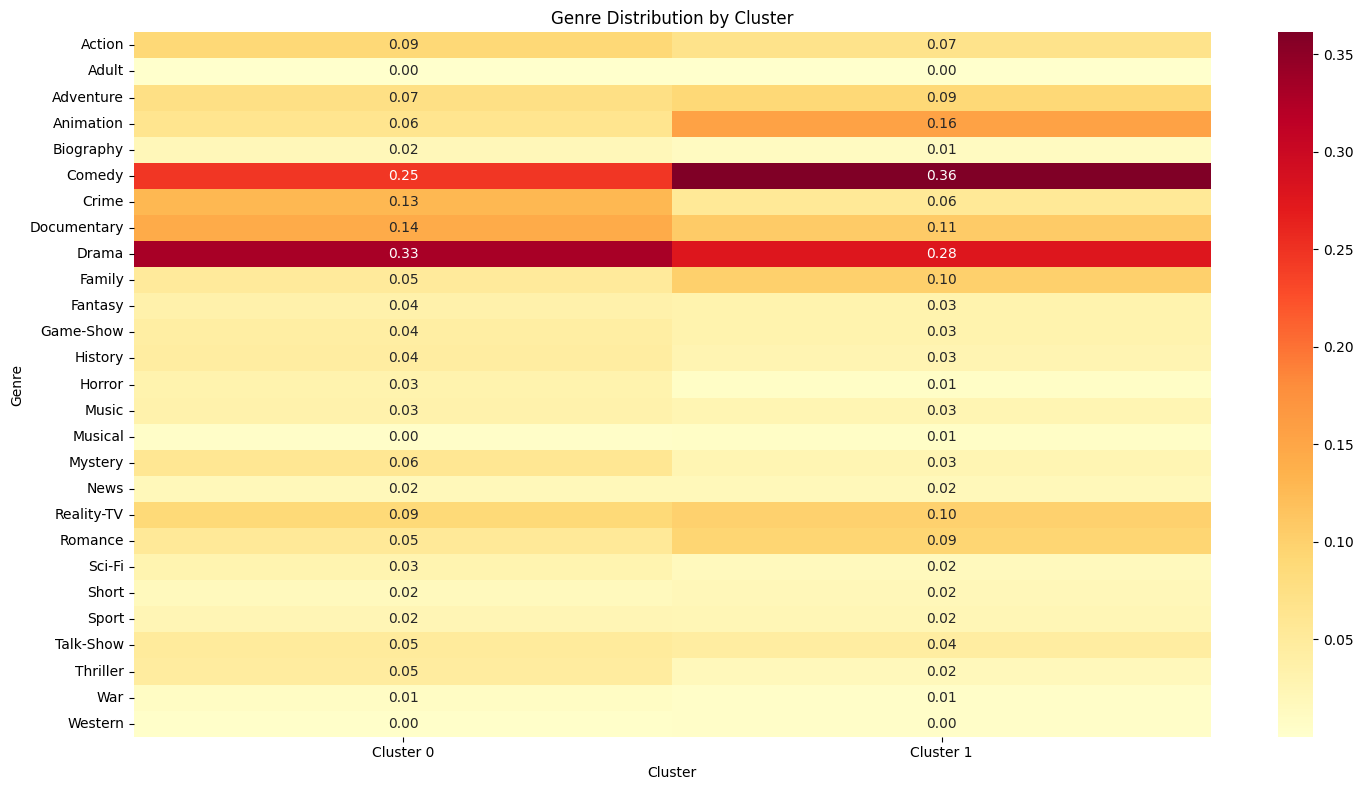

In [31]:
# Step 7: Visualizing clusters with genre information
visualize_clusters_with_genres(cluster_results_df, genres_df)

In [32]:
# Save combined data for GUI application
save_combined_data(pca_df, cluster_labels, genres_df, filename='combined_data.csv')
print("\nAnalysis complete! Check the generated visualizations and combined_data.csv.")

Combined data saved as combined_data.csv

Analysis complete! Check the generated visualizations and combined_data.csv.
